In [1]:
import numpy as np
import pandas as pd
from pathlib import Path
from scipy.optimize import minimize
import scipy.stats as stats
import matplotlib.pyplot as plt


In [2]:
# Chargement des données
df = pd.read_excel('Test.xlsx', sheet_name=0)
df['Date'] = pd.to_datetime(df['Name'])
df = df.set_index('Date')
print(df.head())

# Sélection et renommage
prices = df[['BEL-DS', 'US-DS', 'USD-BIT']].copy()
prices.columns = ['Bel', 'US', 'BTC']
print(prices.head())

# Conversion en numérique et calcul des rendements logs
for col in prices.columns:
    prices[col] = pd.to_numeric(prices[col], errors='coerce')

returns = np.log(prices) - np.log(prices.shift(1))
print(returns.head())

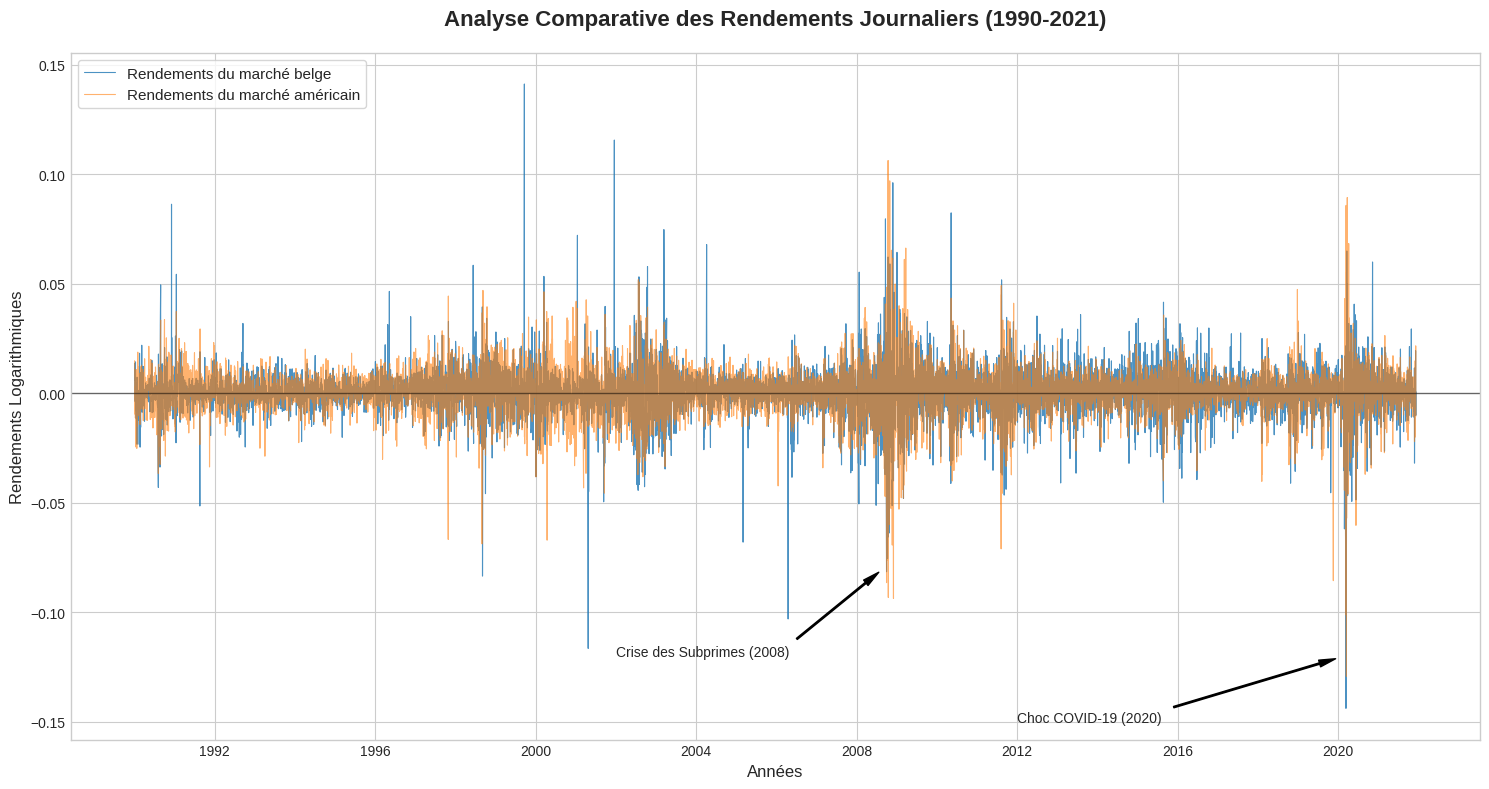

In [3]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# 1. Configuration du style et de la taille
plt.figure(figsize=(15, 8))
plt.style.use('seaborn-v0_8-whitegrid') # Style propre et académique

# 2. Tracé des rendements (on enlève la première ligne qui est NaN)
plt.plot(returns.index, returns['Bel'], label='Rendements du marché belge', color='#1f77b4', alpha=0.8, linewidth=0.8)
plt.plot(returns.index, returns['US'], label='Rendements du marché américain', color='#ff7f0e', alpha=0.6, linewidth=0.8)

# 3. Mise en forme des axes
plt.title('Analyse Comparative des Rendements Journaliers (1990-2021)', fontsize=16, fontweight='bold', pad=20)
plt.xlabel('Années', fontsize=12)
plt.ylabel('Rendements Logarithmiques', fontsize=12)

# 4. Zoom sur le "Volatility Clustering"
# On ajoute des annotations pour les crises majeures afin de guider l'œil du lecteur
plt.annotate('Crise des Subprimes (2008)', xy=(pd.to_datetime('2008-09-01'), -0.08), 
             xytext=(pd.to_datetime('2002-01-01'), -0.12),
             arrowprops=dict(facecolor='black', shrink=0.05, width=1, headwidth=5))

plt.annotate('Choc COVID-19 (2020)', xy=(pd.to_datetime('2020-03-01'), -0.12), 
             xytext=(pd.to_datetime('2012-01-01'), -0.15),
             arrowprops=dict(facecolor='black', shrink=0.05, width=1, headwidth=5))

# 5. Esthétique finale
plt.legend(loc='upper left', frameon=True, fontsize=11)
plt.axhline(0, color='black', linewidth=1, alpha=0.5) # Ligne de zéro pour la référence
plt.tight_layout()

# Affichage
plt.show()

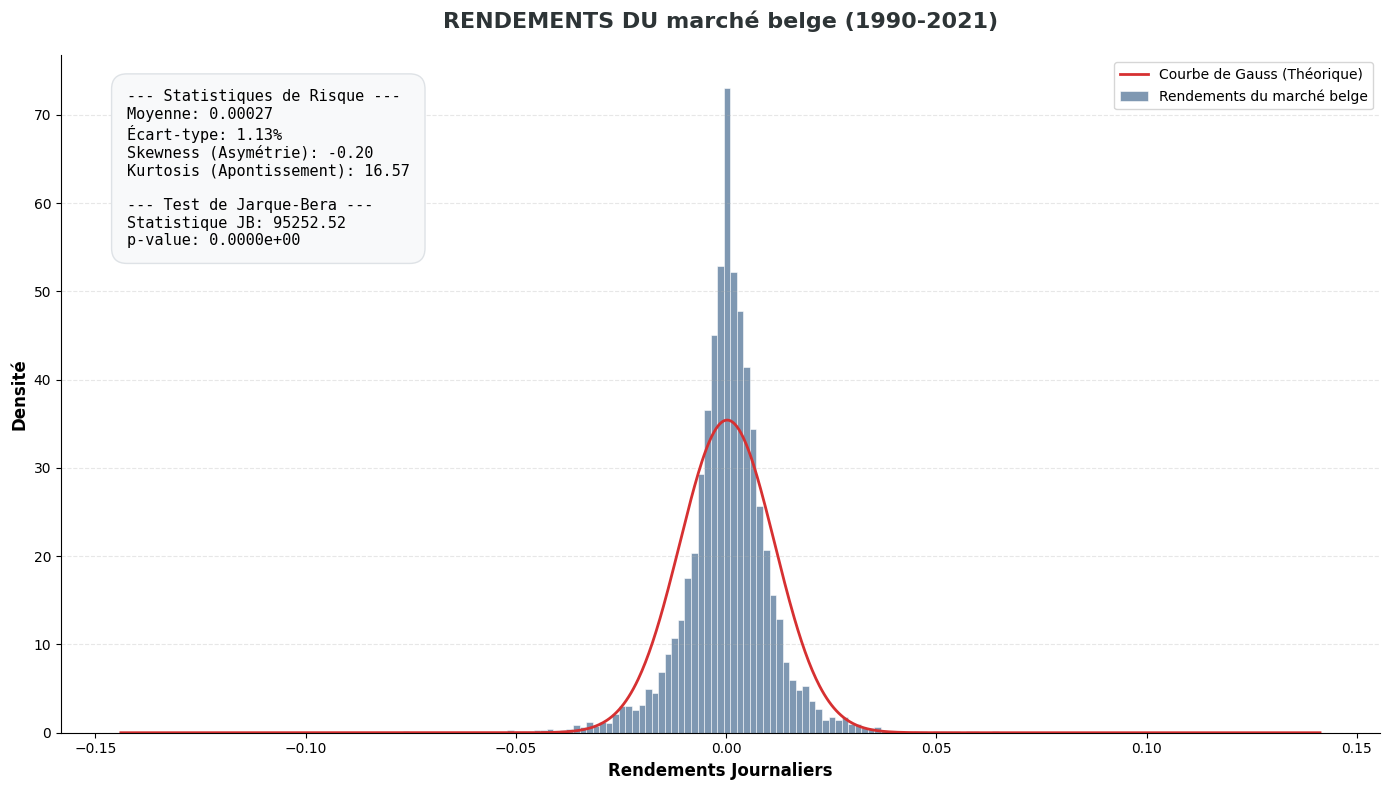

In [4]:
import scipy.stats as stats
import seaborn as sns
from scipy.stats import jarque_bera

# 1. Préparation des données
data_dist = returns['Bel'].dropna()

# 2. Configuration esthétique "Professional White"
plt.style.use('default') # Retour au style standard
plt.figure(figsize=(14, 8), facecolor='white')
ax = plt.gca()
ax.set_facecolor('white')

# 3. Histogramme des rendements (Le réel)
# On utilise un bleu institutionnel avec des contours légers
sns.histplot(data_dist, kde=False, stat="density", color="#003366", alpha=0.5, 
             edgecolor='white', label=f'Rendements du marché belge')

# 4. Superposition de la Loi Normale (Le théorique)
mu, std = data_dist.mean(), data_dist.std()
x = np.linspace(data_dist.min(), data_dist.max(), 1000)
p = stats.norm.pdf(x, mu, std)
plt.plot(x, p, color='#d63031', linewidth=2, label='Courbe de Gauss (Théorique)')

# 5. Calcul du Test de Jarque-Bera
jb_stat, p_value = jarque_bera(data_dist)

# 6. Cartouche de Statistiques Descriptives & Tests
# Ce bloc est crucial pour votre jury de Master
stats_text = (
    f"--- Statistiques de Risque ---\n"
    f"Moyenne: {mu:.5f}\n"
    f"Écart-type: {std:.2%}\n"
    f"Skewness (Asymétrie): {data_dist.skew():.2f}\n"
    f"Kurtosis (Apontissement): {data_dist.kurtosis():.2f}\n\n"
    f"--- Test de Jarque-Bera ---\n"
    f"Statistique JB: {jb_stat:.2f}\n"
    f"p-value: {p_value:.4e}"
)

# Positionnement du texte (Box blanche, texte noir)
plt.text(0.05, 0.95, stats_text, transform=ax.transAxes, fontsize=11,
         verticalalignment='top', family='monospace',
         bbox=dict(boxstyle='round,pad=1', facecolor='#f8f9fa', edgecolor='#dee2e6'))

# 7. Habillage Final
plt.title('RENDEMENTS DU marché belge (1990-2021)', 
          fontsize=16, fontweight='bold', color='#2d3436', pad=20)
plt.xlabel('Rendements Journaliers', fontsize=12, fontweight='bold')
plt.ylabel('Densité', fontsize=12, fontweight='bold')
plt.legend(loc='upper right', frameon=True, fontsize=10)

# Nettoyage des bordures
sns.despine()
plt.grid(axis='y', linestyle='--', alpha=0.3)
plt.tight_layout()

plt.show()

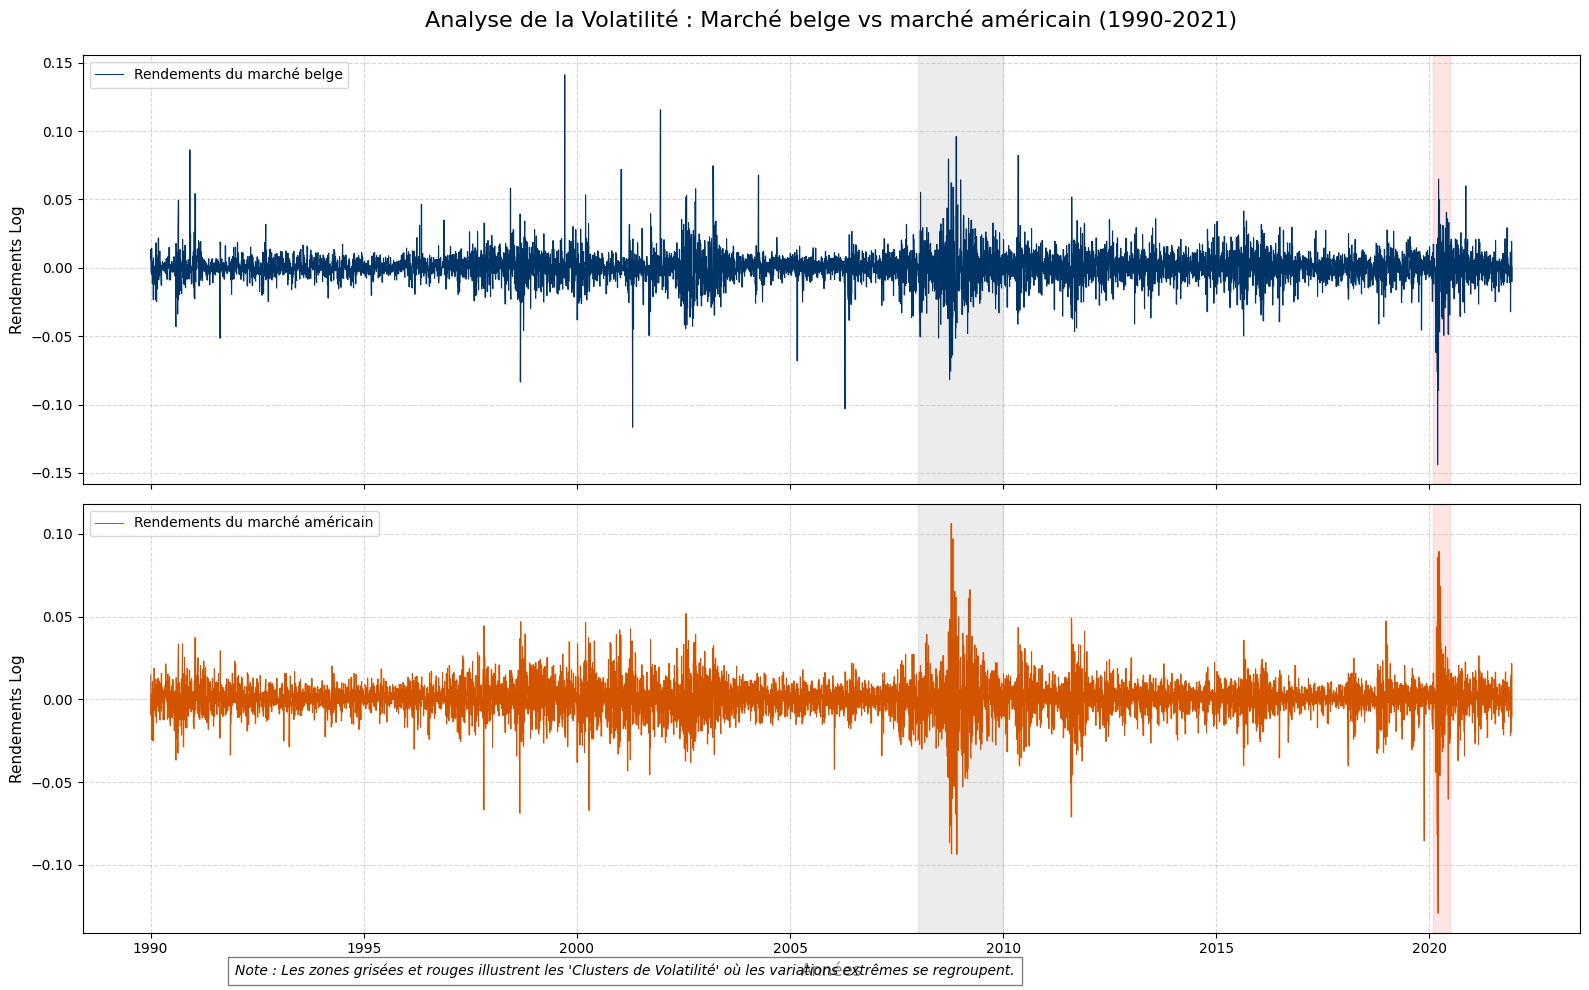

In [5]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import pandas as pd

# 1. Configuration esthétique (Style Professionnel)
plt.rcParams['font.family'] = 'sans-serif'
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(16, 10), sharex=True)
colors = {'Bel': '#003366', 'US': '#D35400'} # Bleu nuit et Orange brûlé

# 2. Graphique marché belge (Haut)
ax1.plot(returns.index, returns['Bel'], color=colors['Bel'], lw=0.7, label='Rendements du marché belge')
ax1.fill_between(returns.index, 0, returns['Bel'], color=colors['Bel'], alpha=0.2)
ax1.set_ylabel('Rendements Log', fontsize=11)
ax1.legend(loc='upper left')
ax1.set_title('Analyse de la Volatilité : Marché belge vs marché américain (1990-2021)', fontsize=16, pad=20)

# 3. Graphique marché américain (Bas)
ax2.plot(returns.index, returns['US'], color=colors['US'], lw=0.7, label='Rendements du marché américain')
ax2.fill_between(returns.index, 0, returns['US'], color=colors['US'], alpha=0.2)
ax2.set_ylabel('Rendements Log', fontsize=11)
ax2.legend(loc='upper left')

# 4. Mise en évidence visuelle du Volatility Clustering (Zones d'ombre)
# On identifie les périodes où la volatilité dépasse un certain seuil (ex: +/- 5%)
for ax in [ax1, ax2]:
    ax.axvspan(pd.to_datetime('2008-01-01'), pd.to_datetime('2009-12-31'), color='gray', alpha=0.15, label='Crise Financière')
    ax.axvspan(pd.to_datetime('2020-02-01'), pd.to_datetime('2020-06-30'), color='red', alpha=0.1, label='Choc COVID-19')
    
    # Formatage des dates
    ax.xaxis.set_major_locator(mdates.YearLocator(5))
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
    ax.grid(True, linestyle='--', alpha=0.5)

# 5. Touche finale "Business Intelligence"
plt.xlabel('Années', fontsize=12)
plt.tight_layout()

# Texte explicatif automatique sur le graphique pour le lecteur
fig.text(0.15, 0.02, "Note : Les zones grisées et rouges illustrent les 'Clusters de Volatilité' où les variations extrêmes se regroupent.", 
         fontsize=10, style='italic', bbox={'facecolor':'white', 'alpha':0.5, 'pad':5})

plt.show()

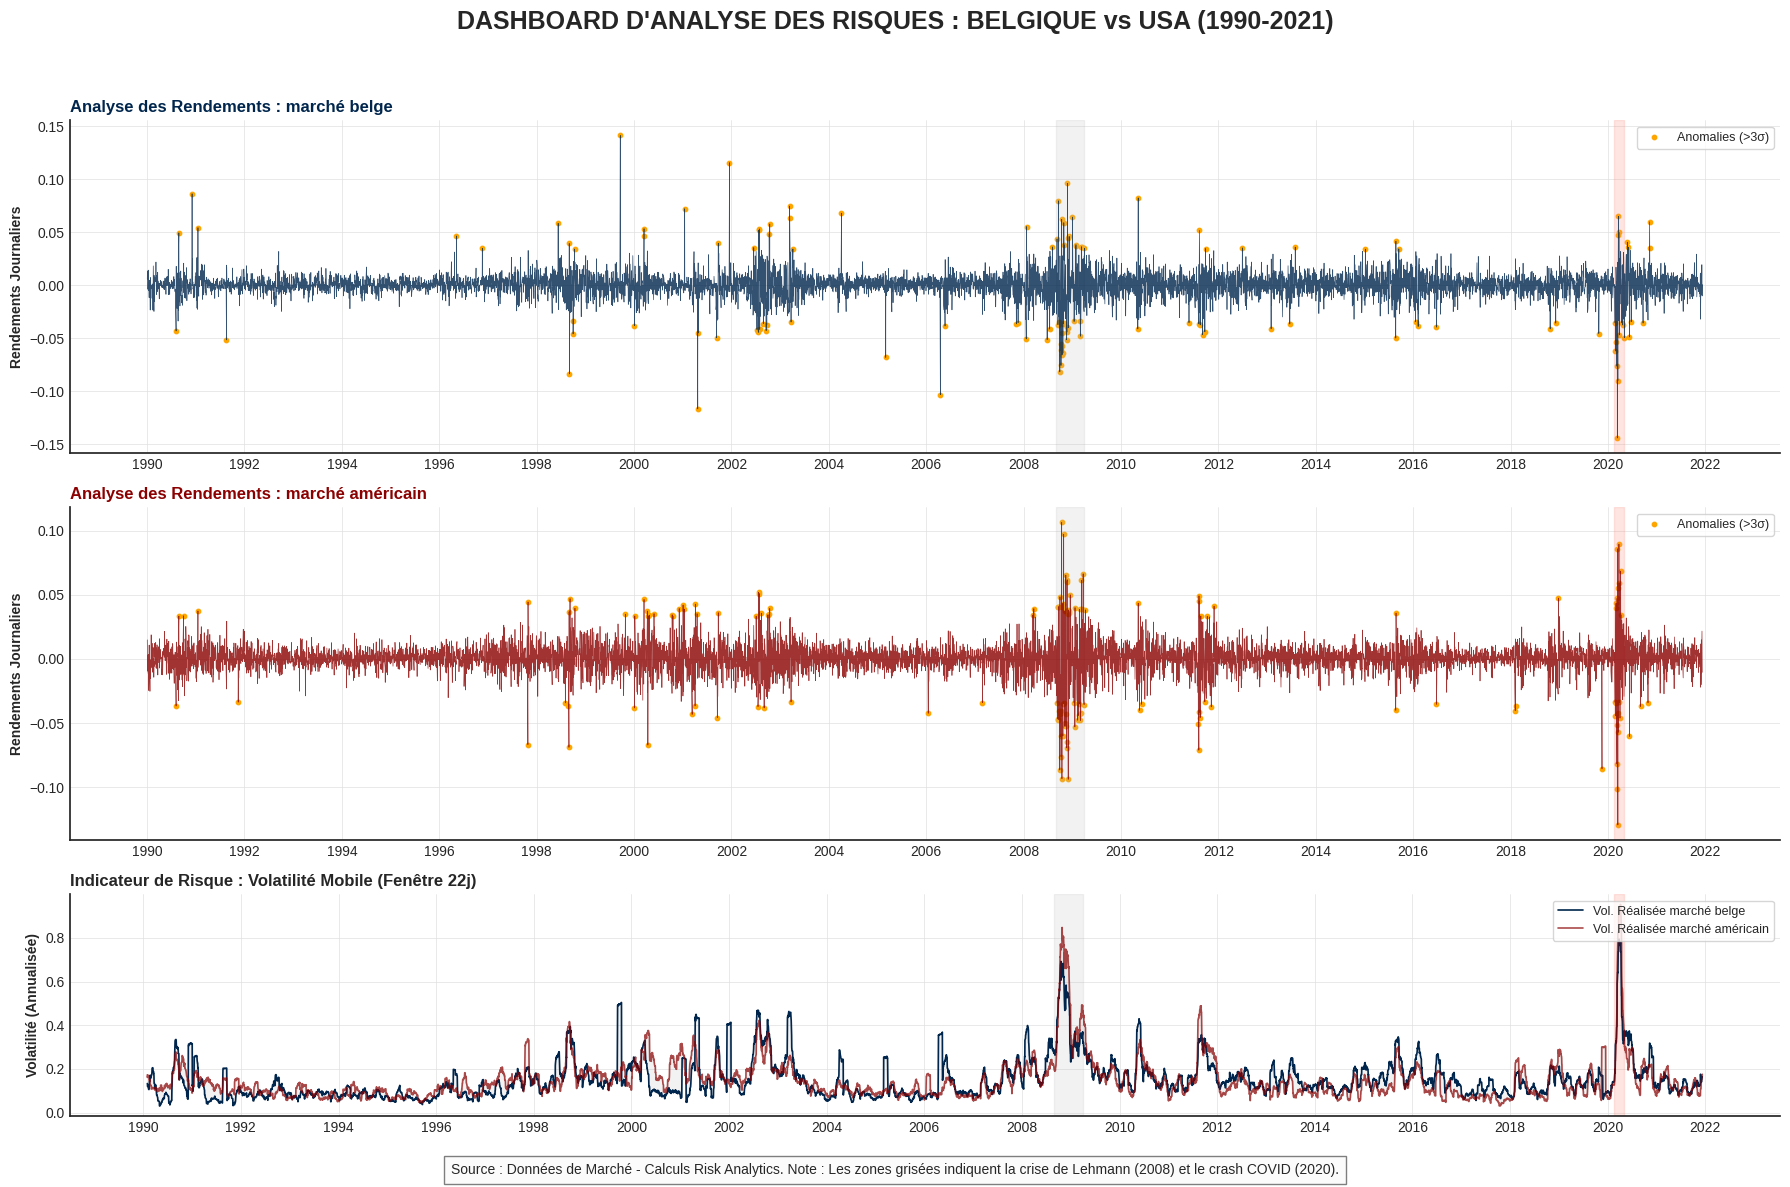

In [6]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import pandas as pd
import numpy as np

# 1. Calculs de Risk Metrics supplémentaires (Fenêtre mobile de 22 jours = 1 mois boursier)
returns['Vol_Bel'] = returns['Bel'].rolling(window=22).std() * np.sqrt(252)
returns['Vol_US'] = returns['US'].rolling(window=22).std() * np.sqrt(252)

# 2. Configuration du canevas "High-End"
plt.style.use('seaborn-v0_8-white')
fig = plt.figure(figsize=(18, 12))
gs = fig.add_gridspec(3, 1, height_ratios=[1.5, 1.5, 1])

ax1 = fig.add_subplot(gs[0]) # Rendements du marché belge
ax2 = fig.add_subplot(gs[1]) # Rendements marché américain
ax3 = fig.add_subplot(gs[2]) # Volatilité Réalisée Comparée

# Couleurs Institutionnelles
color_bel = '#00264d' # Navy Blue
color_us = '#8b0000'  # Dark Red
grid_style = dict(ls='-', lw=0.5, color='#e0e0e0')

# --- SECTION 1 & 2 : RENDEMENTS & CLUSTERS ---
for ax, col, label, color in zip([ax1, ax2], ['Bel', 'US'], ['marché belge', 'marché américain'], [color_bel, color_us]):
    ax.plot(returns.index, returns[col], color=color, lw=0.5, alpha=0.8)
    # Highlight des chocs de volatilité (Z-score > 3)
    extreme_shocks = returns[col][np.abs(returns[col]) > 3 * returns[col].std()]
    ax.scatter(extreme_shocks.index, extreme_shocks, color='orange', s=10, label='Anomalies (>3σ)')
    
    ax.set_ylabel('Rendements Journaliers', fontweight='bold')
    ax.set_title(f'Analyse des Rendements : {label}', loc='left', fontsize=12, fontweight='bold', color=color)
    ax.legend(loc='upper right', frameon=True, fontsize=9)
    ax.grid(**grid_style)

# --- SECTION 3 : VOLATILITÉ RÉALISÉE (ANNUALISÉE) ---
ax3.plot(returns.index, returns['Vol_Bel'], color=color_bel, lw=1.2, label='Vol. Réalisée marché belge')
ax3.plot(returns.index, returns['Vol_US'], color=color_us, lw=1.2, label='Vol. Réalisée marché américain', alpha=0.7)
ax3.fill_between(returns.index, returns['Vol_Bel'], returns['Vol_US'], color='gray', alpha=0.1)

ax3.set_ylabel('Volatilité (Annualisée)', fontweight='bold')
ax3.set_title('Indicateur de Risque : Volatilité Mobile (Fenêtre 22j)', loc='left', fontsize=12, fontweight='bold')
ax3.legend(loc='upper right', frameon=True, fontsize=9)
ax3.grid(**grid_style)

# --- FORMATAGE PROFESSIONNEL ---
for ax in [ax1, ax2, ax3]:
    ax.xaxis.set_major_locator(mdates.YearLocator(2))
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    # Zones de crise historiques
    ax.axvspan(pd.to_datetime('2008-09-01'), pd.to_datetime('2009-03-31'), color='silver', alpha=0.2)
    ax.axvspan(pd.to_datetime('2020-02-15'), pd.to_datetime('2020-05-01'), color='salmon', alpha=0.2)

fig.suptitle('DASHBOARD D\'ANALYSE DES RISQUES : BELGIQUE vs USA (1990-2021)', fontsize=18, fontweight='black', y=0.98)
plt.tight_layout(rect=[0, 0.03, 1, 0.95])

# Caption technique
plt.figtext(0.5, 0.01, "Source : Données de Marché - Calculs Risk Analytics. Note : Les zones grisées indiquent la crise de Lehmann (2008) et le crash COVID (2020).", 
            ha="center", fontsize=10, bbox={"facecolor":"#f9f9f9", "alpha":0.5, "pad":5})

plt.show()

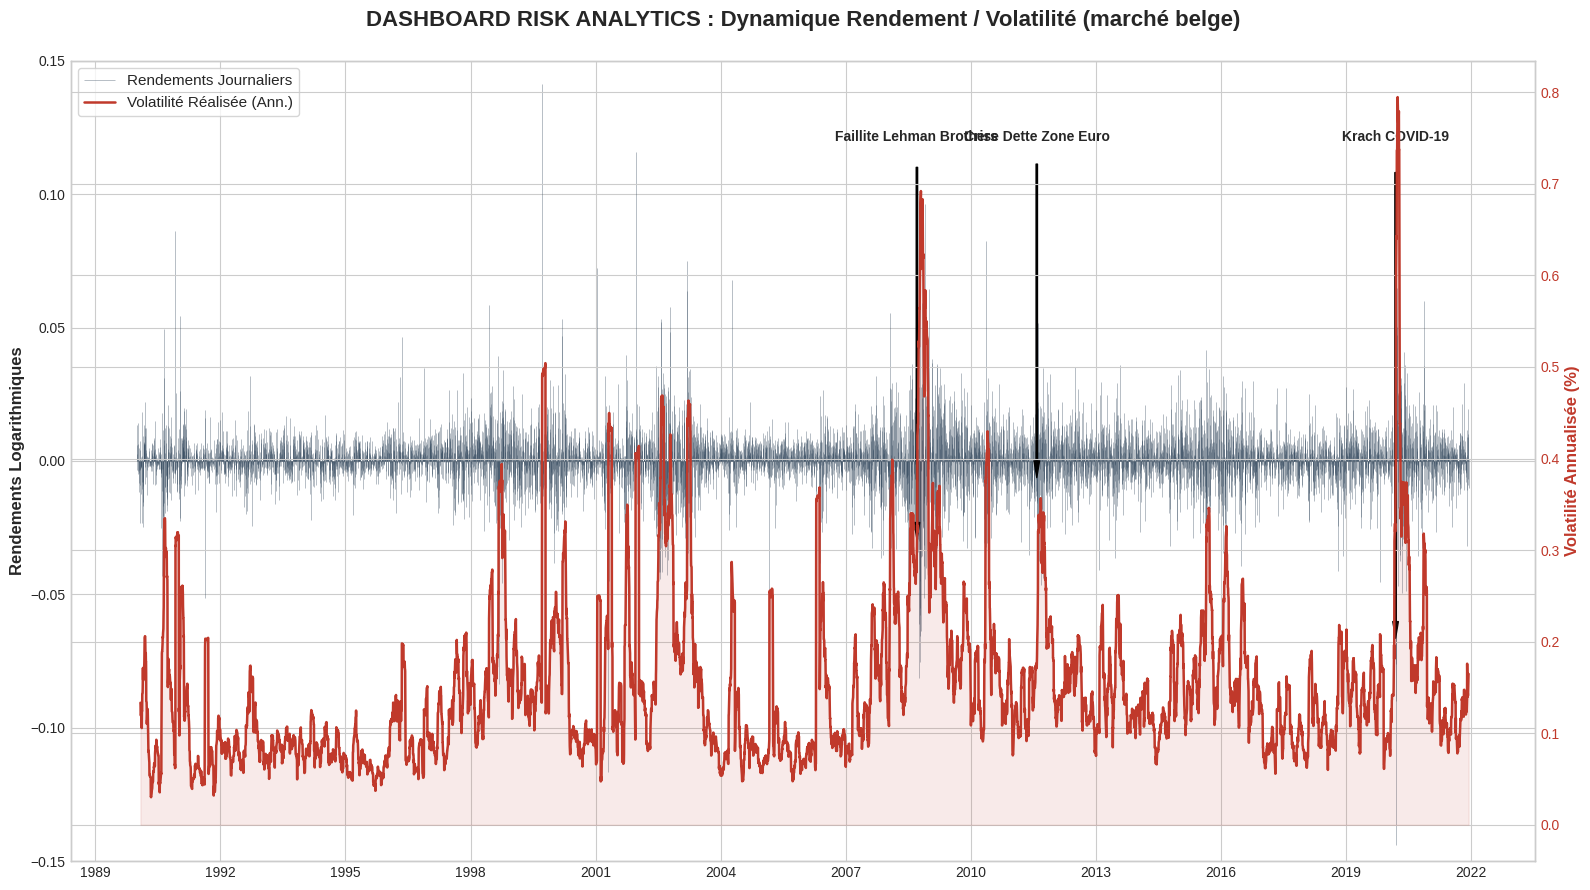

In [7]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import numpy as np

# 1. Calcul de la volatilité réalisée (Rolling Std dev annualisée)
# Fenêtre de 22 jours = 1 mois boursier
returns['Vol_22j'] = returns['Bel'].rolling(window=22).std() * np.sqrt(252)

# 2. Setup de la figure avec un style "Dark-Grid" professionnel
plt.style.use('seaborn-v0_8-whitegrid')
fig, ax1 = plt.subplots(figsize=(16, 9))

# --- AXE 1 : RENDEMENTS (Histogramme vertical fin) ---
ax1.vlines(returns.index, 0, returns['Bel'], color='#34495e', lw=0.5, alpha=0.5, label='Rendements Journaliers')
ax1.set_ylabel('Rendements Logarithmiques', fontsize=12, fontweight='bold')
ax1.set_ylim(-0.15, 0.15) # Centrage sur les variations typiques

# --- AXE 2 : VOLATILITÉ (Ligne de Risque) ---
ax2 = ax1.twinx() # Création du deuxième axe Y
ax2.plot(returns.index, returns['Vol_22j'], color='#c0392b', lw=1.8, label='Volatilité Réalisée (Ann.)')
ax2.fill_between(returns.index, 0, returns['Vol_22j'], color='#c0392b', alpha=0.1)
ax2.set_ylabel('Volatilité Annualisée (%)', fontsize=12, fontweight='bold', color='#c0392b')
ax2.tick_params(axis='y', labelcolor='#c0392b')

# 3. Annotation des évènements systémiques (Le "Top" du Front Office)
# Identification des clusters de volatilité
crises = {
    '2008-09-15': 'Faillite Lehman Brothers',
    '2011-08-01': 'Crise Dette Zone Euro',
    '2020-03-09': 'Krach COVID-19'
}

for date, label in crises.items():
    d = pd.to_datetime(date)
    ax1.annotate(label, xy=(d, returns['Bel'].asof(d)), 
                 xytext=(d, 0.12),
                 arrowprops=dict(facecolor='black', shrink=0.05, width=1, headwidth=4),
                 fontsize=10, fontweight='bold', ha='center')

# 4. Finalisation Esthétique
plt.title('DASHBOARD RISK ANALYTICS : Dynamique Rendement / Volatilité (marché belge)', fontsize=16, fontweight='bold', pad=25)
ax1.xaxis.set_major_locator(mdates.YearLocator(3))
ax1.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))

# Légende combinée
lines, labels = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines + lines2, labels + labels2, loc='upper left', frameon=True, fontsize=11)

plt.tight_layout()
plt.show()

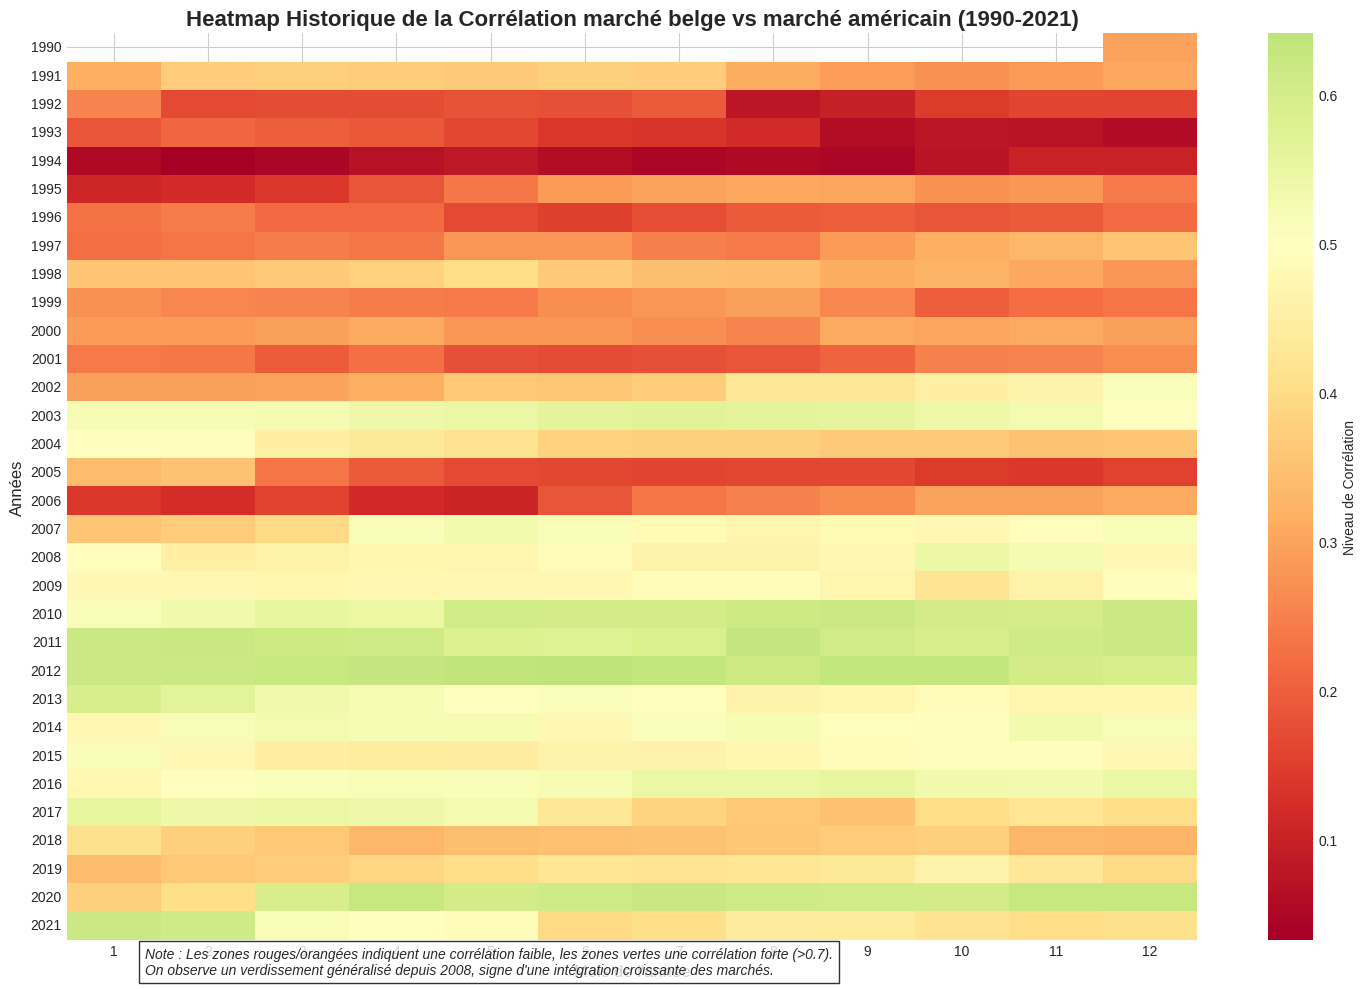

In [8]:
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Calcul de la corrélation glissante (Rolling Correlation) sur 252 jours (1 an boursier)
window_corr = 252
rolling_corr = returns['Bel'].rolling(window=window_corr).corr(returns['US'])

# 2. Préparation des données pour une Heatmap temporelle
# On transforme la série en une matrice (Année x Mois) pour voir l'évolution
corr_df = rolling_corr.dropna().to_frame(name='Correlation')
corr_df['Année'] = corr_df.index.year
corr_df['Mois'] = corr_df.index.month
heatmap_data = corr_df.groupby(['Année', 'Mois'])['Correlation'].mean().unstack()

# 3. Visualisation High-End
plt.figure(figsize=(15, 10))
sns.heatmap(heatmap_data, cmap='RdYlGn', center=0.5, annot=False, cbar_kws={'label': 'Niveau de Corrélation'})

plt.title('Heatmap Historique de la Corrélation marché belge vs marché américain (1990-2021)', fontsize=16, fontweight='bold')
plt.xlabel('Mois de l\'année', fontsize=12)
plt.ylabel('Années', fontsize=12)

# 4. Note sur l'interprétation
plt.figtext(0.1, 0.02, "Note : Les zones rouges/orangées indiquent une corrélation faible, les zones vertes une corrélation forte (>0.7).\nOn observe un verdissement généralisé depuis 2008, signe d'une intégration croissante des marchés.", 
            fontsize=10, style='italic', bbox={'facecolor':'white', 'alpha':0.8})

plt.tight_layout()
plt.show()

In [9]:
#Modèle r1m
b0_1 = 0.000497045
b1_1 = -0.03075519   # signe négatif, conforme à la sortie WinRATS (R1{1} dans l'équation de R1)
b2_1 = 0.272419572

#Modèle r2m
b0_2 = 0.000702742
b1_2 = 0.021415611
b2_2 = -0.032230747  # signe négatif, conforme à la sortie WinRATS (R2{1} dans l'équation de R2)

#Matrice C 
c11 = 0.000025267
c12 = 0.000012765
c13 = 0.000019735

#Matrice A
a11 = 0.034728229
a12 = 0.043461539
a13 = 0.078494566
a21 = 0.017898692
a22 = 0.028937383
a23 = 0.037730814
a31 = 0.033083414
a32 = -0.006357752
a33 = 0.092593697

#Matrice B
b11 = -0.069861126
b12 = 1.501564058
b13 = 0.059844886
b21 = -0.542528699
b22 = 1.750308755
b23 = 0.034600941
b31 = -0.815455871
b32 = 1.193508651
b33 = 0.996477504

In [10]:

 #--- 4. Boucle sur l'ensemble des données ---
# Préparation des données
data_loop = returns[['Bel', 'US']].dropna()
T = len(data_loop)
r1 = data_loop['Bel'].values
r2 = data_loop['US'].values

# Initialisation des vecteurs pour stocker les résultats
r1m = np.zeros(T)
r2m = np.zeros(T)
eps1 = np.zeros(T)
eps2 = np.zeros(T)
eps1_2 = np.zeros(T)
eps2_2 = np.zeros(T)
eps_cross = np.zeros(T)

eps1[0] = r1[0]
eps2[0] = r2[0]
eps_cross[0] = eps1[0] * eps2[0]

for t in range(1, T):
    r1m[t] = b0_1 + b1_1* r1[t-1] + b2_1 * r2[t-1]
    r2m[t] = b0_2 + b1_2 * r1[t-1] + b2_2 * r2[t-1]
    eps1[t] = r1[t] - r1m[t]
    eps2[t] = r2[t] - r2m[t]
    eps1_2[t] = eps1[t] * eps1[t]
    eps2_2[t] = eps2[t] * eps2[t]
    eps_cross[t] = eps1[t] * eps2[t]

# Création d'un DataFrame pour aligner les résultats numpy avec l'index temporel original
df_eps = pd.DataFrame({'eps1': eps1, 'eps2': eps2}, index=data_loop.index)

# Extraction des données sur la plage de dates spécifiée
date_start = '1990-01-03'
date_end = '2021-07-23'

subset = df_eps.loc[date_start:date_end]

# Création des variables demandées
eps1_col = subset['eps1'].values
eps2_col = subset['eps2'].values

# Initialisation des vecteurs de variance pour stocker les résultats
h11_t = np.zeros(T)
h12_t = np.zeros(T)
h22_t = np.zeros(T)

# Valeurs initiales (Variance inconditionnelle empirique)  t=1  
h11_t[0] = np.var(eps1_col)
h22_t[0] = np.var(eps2_col)
h12_t[0] = np.cov(eps1_col, eps2_col)[0, 1]

print(h11_t[0], h12_t[0], h22_t[0])

#Calcul valeur t=2
h11_t[1] = c11 + a11*eps1[0]**2 + a12*eps_cross[0] + a13*eps2[0]**2 + b11*h11_t[0] + b12*h12_t[0] + b13*h22_t[0]
h12_t[1] = c12 + a21*eps1[0]**2 + a22*eps_cross[0] + a23*eps2[0]**2 + b21*h11_t[0] + b22*h12_t[0] + b23*h22_t[0]
h22_t[1] = c13 + a31*eps1[0]**2 + a32*eps_cross[0] + a33*eps2[0]**2 + b31*h11_t[0] + b32*h12_t[0] + b33*h22_t[0]


#Calcul valeur t=3 to T
for t in range(2, T): 
    h11_t[t] = c11 + a11*eps1[t-1]**2 + a12*eps_cross[t-1] + a13*eps2[t-1]**2 + b11*h11_t[t-1] + b12*h12_t[t-1] + b13*h22_t[t-1]
    h12_t[t] = c12 + a21*eps1[t-1]**2 + a22*eps_cross[t-1] + a23*eps2[t-1]**2 + b21*h11_t[t-1] + b22*h12_t[t-1] + b23*h22_t[t-1]
    h22_t[t] = c13 + a31*eps1[t-1]**2 + a32*eps_cross[t-1] + a33*eps2[t-1]**2 + b31*h11_t[t-1] + b32*h12_t[t-1] + b33*h22_t[t-1]
      



0.00011975539309118193 5.6830451930625365e-05 0.0001223372078612848


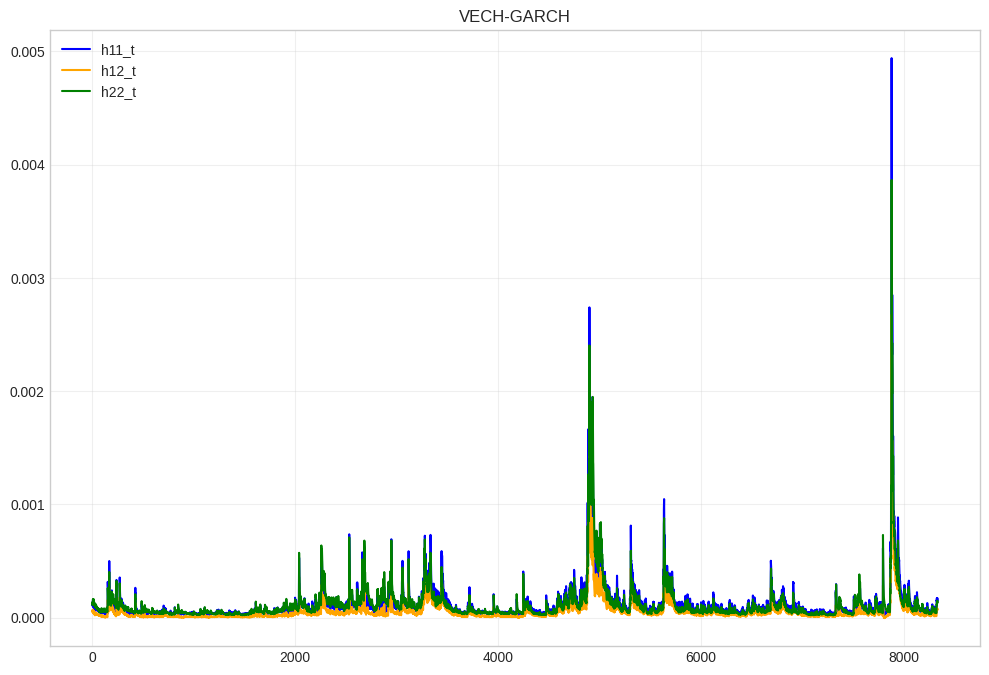

In [11]:
plt.figure(figsize=(12,8))
plt.plot(h11_t, 'b-', label='h11_t', lw=1.5)
plt.plot(h12_t, 'orange', label='h12_t', lw=1.5)
plt.plot(h22_t, 'g-', label='h22_t', lw=1.5)
plt.legend(); plt.grid(alpha=0.3); plt.title('VECH-GARCH'); plt.show()


In [12]:
# Création d'un DataFrame pour aligner les résultats numpy avec l'index temporel original
df_VaR = pd.DataFrame({'r1': r1, 'r1m': r1m, 'h11_t': h11_t}, index=data_loop.index)

# Extraction des données sur la plage de dates spécifiée
date_start = '2021-07-23'
date_end = '2021-12-09'

subset = df_VaR.loc[date_start:date_end]

# Création des variables demandées
n_subset = len(subset)
r1_new = subset['r1'].values
r1m_new = subset['r1m'].values
h11_t_new = subset['h11_t'].values

VaR = np.zeros(n_subset)
Val_V = np.zeros(n_subset)
Perte = np.zeros(n_subset)


Val_V[0] = 100000 * (1 + r1_new[0])
Val_V[1] = Val_V[0] * (1 + r1_new[1])
Perte[0] = 100000 - Val_V[0]
Perte[1] = Val_V[0] - Val_V[1]

for t in range(2, n_subset):
    Val_V[t] = Val_V[t-1] * (1 + r1_new[t])
    Perte[t] = Val_V[t-1] - Val_V[t]



VaR[0] = 100000 * ((-r1m_new[0] + 1.645 * (h11_t_new[0]**0.5)))
for t in range(1, n_subset):
    VaR[t] = Val_V[t-1]*((-r1m_new[t]+ 1.645*(h11_t_new[t]**0.5)))




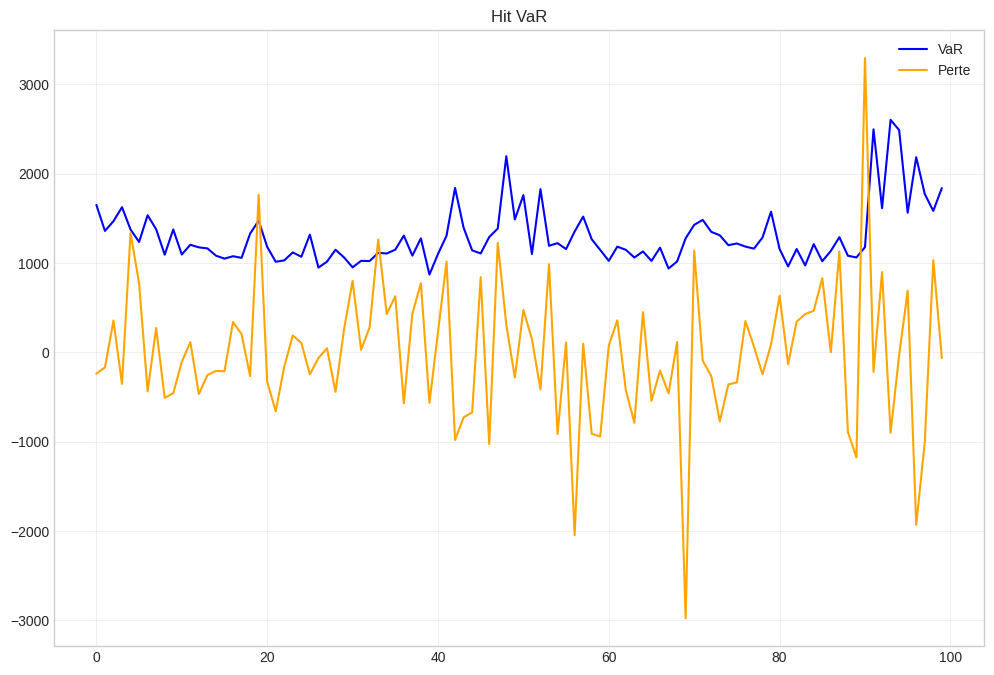

In [13]:
plt.figure(figsize=(12,8))
plt.plot(VaR, 'b-', label='VaR', lw=1.5)
plt.plot(Perte, 'orange', label='Perte', lw=1.5)
plt.legend(); plt.grid(alpha=0.3); plt.title('Hit VaR'); plt.show()

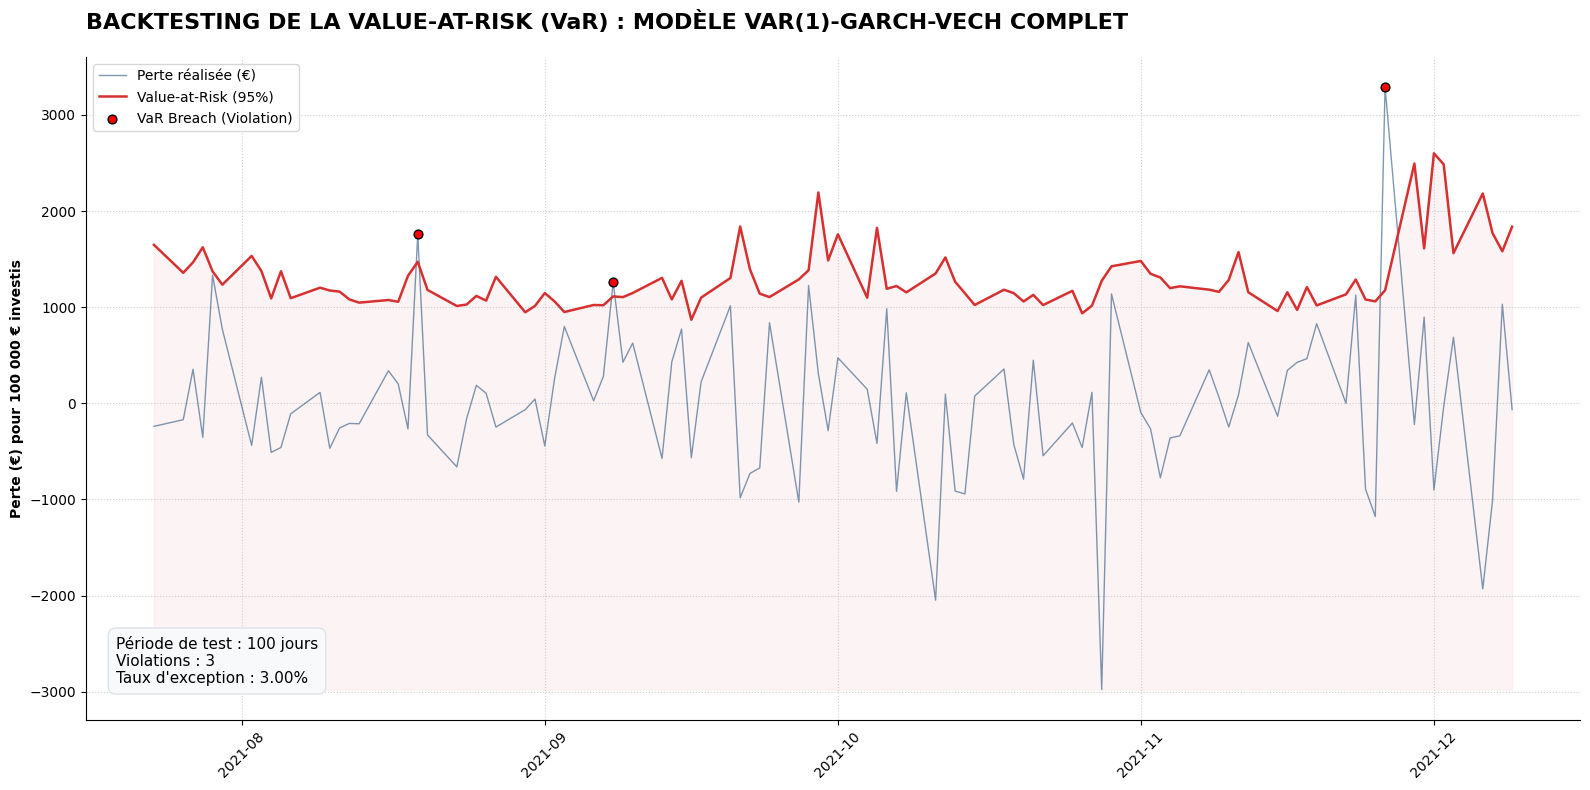

In [14]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import numpy as np

# --- 1. SYNCHRONISATION DES DIMENSIONS ---
# On s'assure que l'index correspond aux 100 dernières valeurs si vos variables n'ont que 100 points
if len(Perte) != len(data_loop):
    # On prend les n dernières dates de l'index correspondant à la taille de la VaR
    plot_index = data_loop.index[-len(Perte):]
else:
    plot_index = data_loop.index

# --- 2. CONFIGURATION DU GRAPHIQUE (Fond Blanc Clean) ---
plt.style.use('default')
fig, ax = plt.subplots(figsize=(16, 8), facecolor='white')
ax.set_facecolor('white')

# 3. Identification des violations
hits = Perte > VaR 

# 4. Tracé des séries avec le bon index synchronisé
ax.plot(plot_index, Perte, color='#003366', lw=1, alpha=0.5, label='Perte réalisée (€)')
ax.plot(plot_index, VaR, color='#d63031', lw=1.8, label='Value-at-Risk (95%)')

# 5. Marquage des violations (Hits)
ax.scatter(plot_index[hits], Perte[hits], color='red', s=40, label='VaR Breach (Violation)', zorder=5, edgecolor='black')

# 6. Remplissage esthétique
ax.fill_between(plot_index, VaR, Perte.min(), color='#d63031', alpha=0.05)

# 7. Habillage Front Office
ax.set_title('BACKTESTING DE LA VALUE-AT-RISK (VaR) : MODÈLE VAR(1)-GARCH-VECH COMPLET', 
             loc='left', fontsize=16, fontweight='bold', pad=20)
ax.set_ylabel('Perte (€) pour 100 000 € investis', fontweight='bold')

# Statistiques d'audit
nb_hits = np.sum(hits)
tx_exception = (nb_hits / len(Perte)) * 100
stats_audit = (f"Période de test : {len(Perte)} jours\n"
               f"Violations : {nb_hits}\n"
               f"Taux d'exception : {tx_exception:.2f}%")

ax.text(0.02, 0.05, stats_audit, transform=ax.transAxes, fontsize=11,
        verticalalignment='bottom', bbox=dict(boxstyle='round,pad=0.5', facecolor='#f8f9fa', edgecolor='#dee2e6'))

# Formatage des dates pour voir l'évolution
ax.xaxis.set_major_locator(mdates.MonthLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
plt.xticks(rotation=45)
ax.grid(True, linestyle=':', alpha=0.6)
ax.legend(loc='upper left', frameon=True)
sns.despine()

plt.tight_layout()
plt.show()

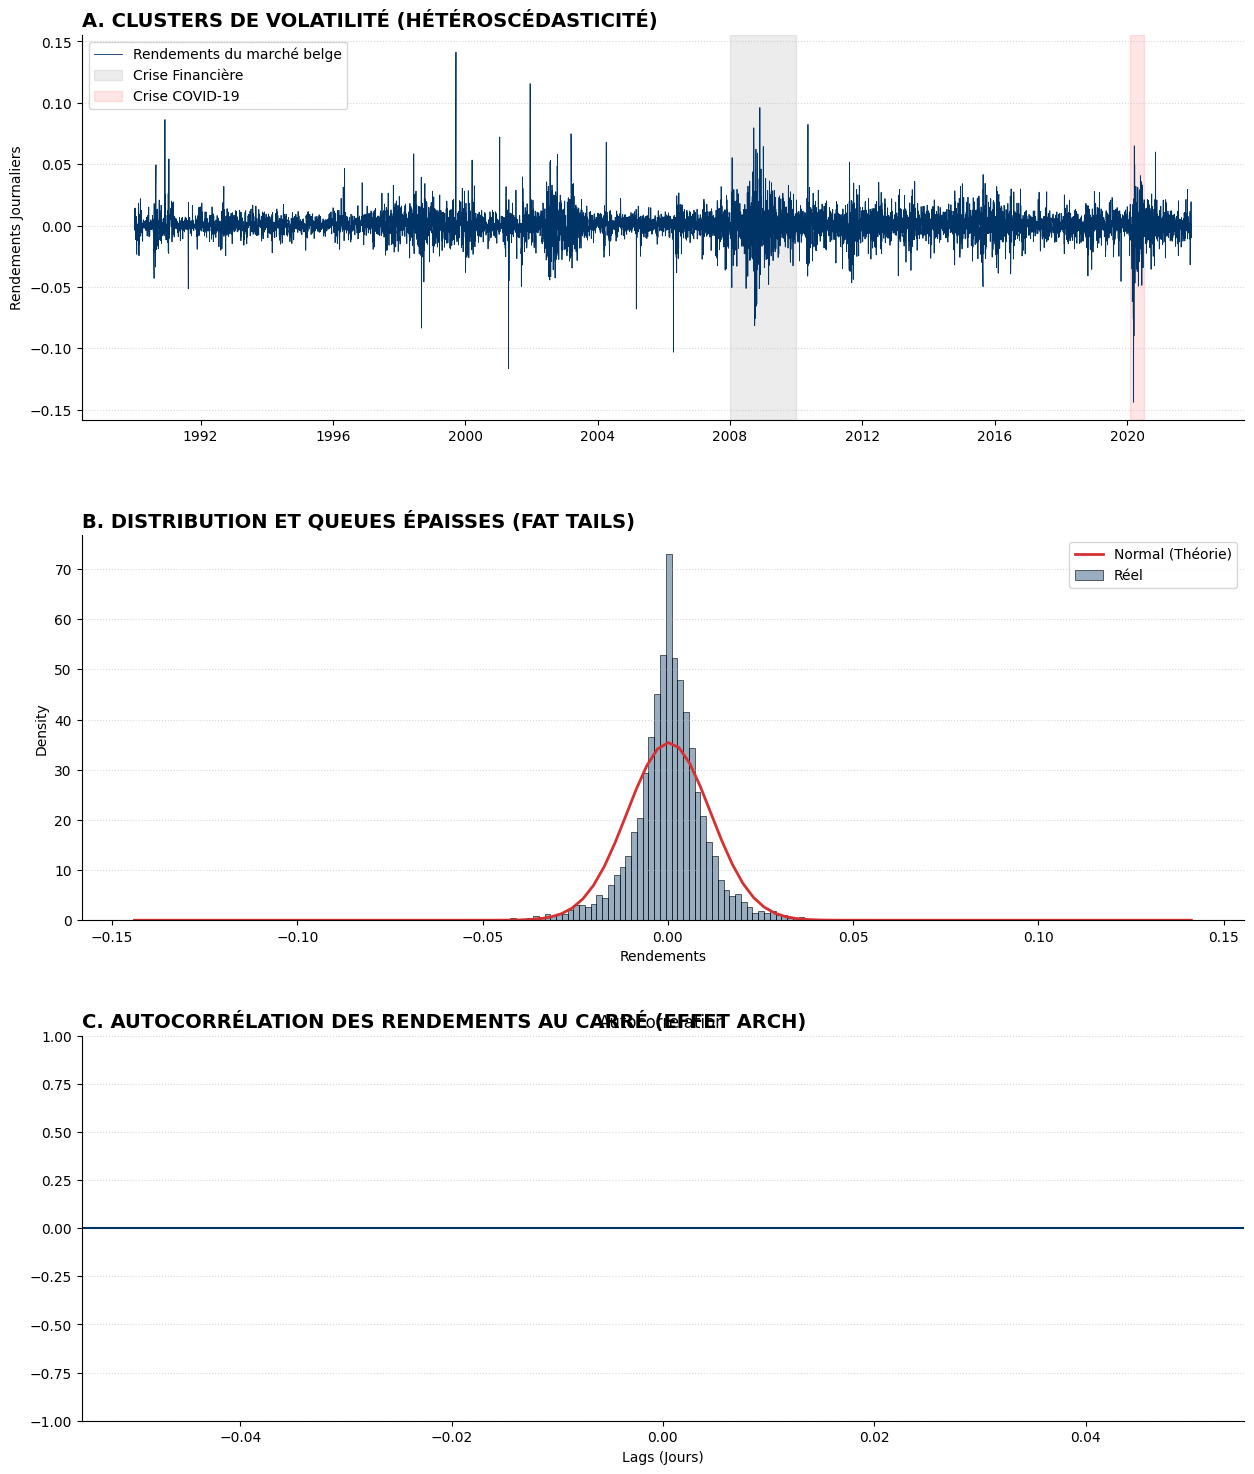

In [15]:
import scipy.stats as stats
import seaborn as sns
from statsmodels.graphics.tsaplots import plot_acf

# 1. Configuration de la figure (3 graphiques en 1)
fig, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize=(15, 18), facecolor='white')
plt.subplots_adjust(hspace=0.3)

# --- GRAPHIQUE 1 : CLUSTERS DE VOLATILITÉ ---
ax1.plot(returns.index, returns['Bel'], color='#003366', lw=0.6, label='Rendements du marché belge')
ax1.axvspan('2008-01-01', '2009-12-31', color='gray', alpha=0.15, label='Crise Financière')
ax1.axvspan('2020-02-01', '2020-06-30', color='red', alpha=0.1, label='Crise COVID-19')
ax1.set_title('A. CLUSTERS DE VOLATILITÉ (HÉTÉROSCÉDASTICITÉ)', loc='left', fontweight='bold', fontsize=14)
ax1.set_ylabel('Rendements Journaliers')
ax1.legend(loc='upper left')

# --- GRAPHIQUE 2 : LEPTOKURTICITÉ (DISTRIBUTION) ---
sns.histplot(returns['Bel'], kde=False, stat="density", color="#003366", alpha=0.4, ax=ax2, label='Réel')
mu, std = returns['Bel'].mean(), returns['Bel'].std()
x = np.linspace(returns['Bel'].min(), returns['Bel'].max(), 100)
ax2.plot(x, stats.norm.pdf(x, mu, std), color='#d63031', lw=2, label='Normal (Théorie)')
ax2.set_title('B. DISTRIBUTION ET QUEUES ÉPAISSES (FAT TAILS)', loc='left', fontweight='bold', fontsize=14)
ax2.set_xlabel('Rendements')
ax2.legend()

# --- GRAPHIQUE 3 : DÉPENDANCE TEMPORELLE (ACF DES CARRÉS) ---
# L'ACF des carrés prouve que la variance n'est pas un bruit blanc
plot_acf(returns['Bel']**2, lags=40, ax=ax3, color='#003366', vlines_kwargs={"colors": '#003366'})
ax3.set_title('C. AUTOCORRÉLATION DES RENDEMENTS AU CARRÉ (EFFET ARCH)', loc='left', fontweight='bold', fontsize=14)
ax3.set_xlabel('Lags (Jours)')

# Nettoyage final
for ax in [ax1, ax2, ax3]:
    sns.despine(ax=ax)
    ax.grid(axis='y', linestyle=':', alpha=0.5)

plt.show()

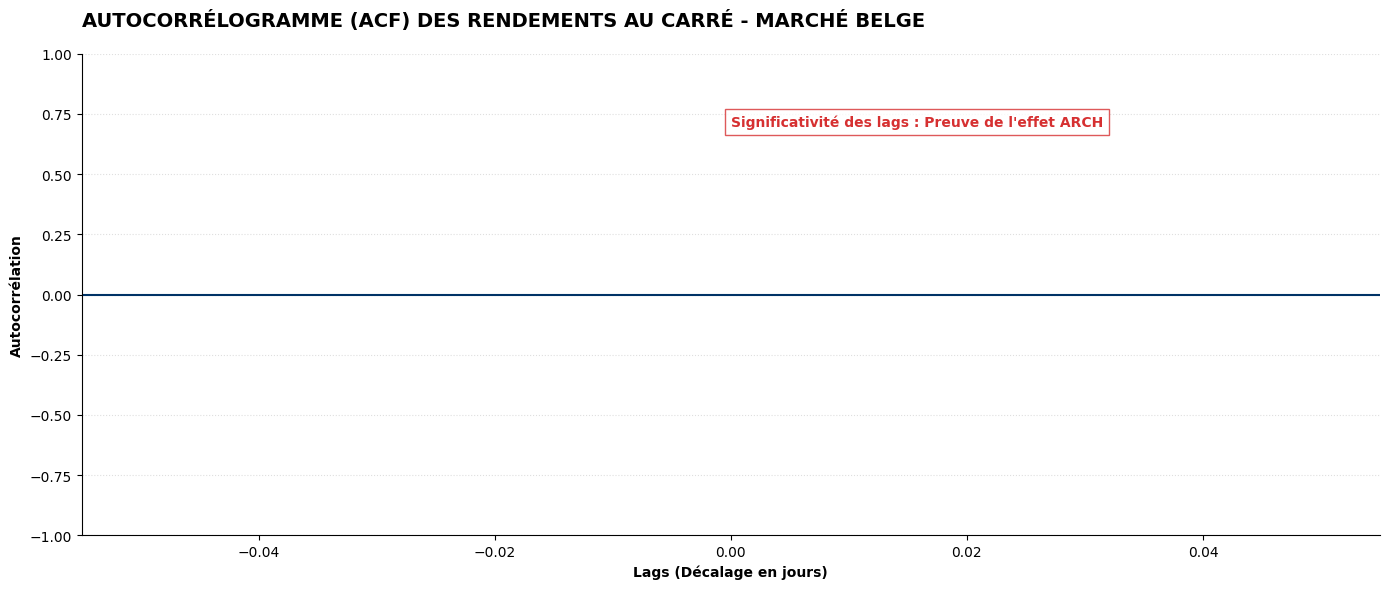

In [16]:
from statsmodels.graphics.tsaplots import plot_acf

# 1. Configuration de la figure
fig, ax = plt.subplots(figsize=(14, 6), facecolor='white')
ax.set_facecolor('white')

# 2. Calcul et tracé de l'ACF des rendements au carré
# On utilise les carrés pour capturer la structure de la variance
plot_acf(returns['Bel']**2, lags=40, ax=ax, alpha=0.05, 
         color='#003366', vlines_kwargs={"colors": '#003366'},
         title=None)

# 3. Habillage "Research Grade"
ax.set_title('AUTOCORRÉLOGRAMME (ACF) DES RENDEMENTS AU CARRÉ - MARCHÉ BELGE', 
             fontsize=14, fontweight='bold', loc='left', pad=20)
ax.set_xlabel('Lags (Décalage en jours)', fontweight='bold')
ax.set_ylabel('Autocorrélation', fontweight='bold')

# Ajout d'une note explicative sur le graphique
ax.text(0.5, 0.85, "Significativité des lags : Preuve de l'effet ARCH", 
        transform=ax.transAxes, color='#d63031', fontweight='bold',
        bbox=dict(facecolor='white', alpha=0.8, edgecolor='#d63031'))

# Nettoyage
sns.despine()
plt.grid(axis='y', linestyle=':', alpha=0.4)
plt.tight_layout()
plt.show()

In [17]:
# Test de Kupiec (proportion de violations, POF) : le taux observé est-il compatible avec 5 % ?
from scipy.stats import chi2, binom

def kupiec_pof(nb_violations, n, p=0.05):
    """Statistique du rapport de vraisemblance de Kupiec et sa p-value (loi du khi-deux à 1 degré de liberté)."""
    x, pi = nb_violations, nb_violations / n
    ll0 = (n - x) * np.log(1 - p) + x * np.log(p)
    ll1 = (n - x) * np.log(1 - pi) + (x * np.log(pi) if x > 0 else 0.0)
    lr = -2 * (ll0 - ll1)
    return lr, 1 - chi2.cdf(lr, 1)

n_obs, x_obs = len(Perte), int(np.sum(Perte > VaR))
lr, pval = kupiec_pof(x_obs, n_obs, p=0.05)
bas, haut = int(binom.ppf(0.025, n_obs, 0.05)), int(binom.ppf(0.975, n_obs, 0.05))
print(f"Violations : {x_obs} sur {n_obs} jours (attendu : {0.05 * n_obs:.0f})")
print(f"Kupiec LR = {lr:.3f}, p-value = {pval:.3f} -> " + ("modèle non rejeté à 5 %" if pval > 0.05 else "modèle rejeté à 5 %"))
print(f"Zone d'acceptation à 95 % : de {bas} à {haut} violations")


Violations : 3 sur 100 jours (attendu : 5)
Kupiec LR = 0.977, p-value = 0.323 -> modèle non rejeté à 5 %
Zone d'acceptation à 95 % : de 1 à 10 violations
